<a href="https://colab.research.google.com/github/aditibande/BlindDoc/blob/main/FHE_Medical_Screening.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q uv
!uv venv --python 3.10 /content/fhe_env
!uv pip install --python /content/fhe_env/bin/python concrete-ml scikit-learn

Using CPython 3.10.22
Creating virtual environment at: fhe_env
Activate with: source fhe_env/bin/activate
Using Python 3.10.22 environment at: fhe_env
Resolved 74 packages in 771ms
Prepared 74 packages in 1m 24s
Installed 74 packages in 859ms
 + anyio==4.15.1
 + brevitas==0.10.2
 + click==8.5.0
 + cloudpickle==3.1.2
 + coloredlogs==15.0.1
 + concrete-ml==1.9.0
 + concrete-ml-extensions==0.1.9
 + concrete-python==2.10.0
 + dependencies==2.0.1
 + dill==0.4.1
 + exceptiongroup==1.3.1
 + filelock==4.1.0
 + flatbuffers==25.12.19
 + fsspec==2026.9.0
 + h11==0.16.0
 + hf-xet==1.7.1
 + httpcore2==2.14.0
 + httpx2==2.14.0
 + huggingface-hub==2.3.0
 + humanfriendly==10.0
 + hummingbird-ml==0.4.11
 + idna==3.20
 + importlib-resources==7.1.0
 + jinja2==3.1.6
 + joblib==1.6.0
 + jsonpickle==4.1.4
 + markupsafe==3.0.4
 + mpmath==1.3.0
 + networkx==3.4.2
 + numpy==1.26.4
 + nvidia-cublas-cu12==12.1.3.1
 + nvidia-cuda-cupti-cu12==12.1.105
 + nvidia-cuda-nvrtc-cu12==12.1.105
 + nvidia-cuda-runtime-cu12

In [ ]:
!/content/fhe_env/bin/python -c "import sys, importlib.metadata as m; import concrete.ml; print(sys.version); print('concrete-ml', m.version('concrete-ml'))"

3.10.22 (main, Oct  9 2026, 15:21:30) [Clang 22.1.3 ]
concrete-ml 1.9.0


In [ ]:
%%writefile fhe_demo.py
import time
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression as SkLogReg
from sklearn.metrics import accuracy_score
from concrete.ml.sklearn import LogisticRegression as FheLogReg

data = load_breast_cancer()
X = data.data[:, :10]
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

plain_model = SkLogReg(max_iter=1000)
plain_model.fit(X_train, y_train)
t = time.time()
plain_pred = plain_model.predict(X_test)
plain_time = time.time() - t
plain_acc = accuracy_score(y_test, plain_pred)

fhe_model = FheLogReg(n_bits=8)
fhe_model.fit(X_train, y_train)

t = time.time()
fhe_model.compile(X_train)
compile_time = time.time() - t

t = time.time()
fhe_model.fhe_circuit.keygen()
keygen_time = time.time() - t

quant_pred = fhe_model.predict(X_test)
quant_acc = accuracy_score(y_test, quant_pred)

N = 20
t = time.time()
fhe_pred = fhe_model.predict(X_test[:N], fhe="execute")
fhe_time = time.time() - t

fhe_acc = accuracy_score(y_test[:N], fhe_pred)
agreement = np.mean(fhe_pred == quant_pred[:N])

print("Plaintext accuracy:", round(plain_acc, 4))
print("Plaintext time (", len(X_test), "samples):", round(plain_time, 5), "s")
print("Quantized clear accuracy:", round(quant_acc, 4))
print("Compile time:", round(compile_time, 2), "s")
print("Key generation time:", round(keygen_time, 2), "s")
print("Encrypted accuracy (", N, "samples):", round(fhe_acc, 4))
print("Encrypted vs quantized agreement:", round(agreement, 4))
print("Encrypted total time:", round(fhe_time, 2), "s")
print("Encrypted per sample:", round(fhe_time / N, 3), "s")

Writing fhe_demo.py


In [ ]:
!/content/fhe_env/bin/python fhe_demo.py

Plaintext accuracy: 0.8947
Plaintext time ( 114 samples): 0.00047 s
Quantized clear accuracy: 0.8947
Compile time: 1.24 s
Key generation time: 0.01 s
Encrypted accuracy ( 20 samples): 0.85
Encrypted vs quantized agreement: 1.0
Encrypted total time: 0.43 s
Encrypted per sample: 0.021 s


In [ ]:
%%writefile fhe_demo2.py
import time
import shutil
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression as SkLogReg
from sklearn.metrics import accuracy_score
from concrete.ml.sklearn import LogisticRegression as FheLogReg
from concrete.ml.deployment import FHEModelDev, FHEModelClient, FHEModelServer

data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

plain_model = SkLogReg(max_iter=1000)
plain_model.fit(X_train, y_train)
t = time.time()
plain_pred = plain_model.predict(X_test)
plain_time = time.time() - t
plain_acc = accuracy_score(y_test, plain_pred)

fhe_model = FheLogReg(n_bits=8)
fhe_model.fit(X_train, y_train)
t = time.time()
fhe_model.compile(X_train)
compile_time = time.time() - t

quant_pred = fhe_model.predict(X_test)
quant_acc = accuracy_score(y_test, quant_pred)

t = time.time()
fhe_pred = fhe_model.predict(X_test, fhe="execute")
fhe_time = time.time() - t
fhe_acc = accuracy_score(y_test, fhe_pred)
agreement = np.mean(fhe_pred == quant_pred)

print("Samples:", len(X_test), "Features:", X.shape[1])
print("Plaintext accuracy:", round(plain_acc, 4))
print("Plaintext time per sample:", plain_time / len(X_test), "s")
print("Quantized clear accuracy:", round(quant_acc, 4))
print("Encrypted accuracy:", round(fhe_acc, 4))
print("Encrypted vs quantized agreement:", round(agreement, 4))
print("Encrypted time per sample:", round(fhe_time / len(X_test), 4), "s")
print("Compile time:", round(compile_time, 2), "s")

shutil.rmtree("deploy", ignore_errors=True)
shutil.rmtree("keys", ignore_errors=True)
FHEModelDev("deploy", fhe_model).save()

client = FHEModelClient("deploy", key_dir="keys")
client.load()
t = time.time()
client.generate_private_and_evaluation_keys(force=True)
keygen_time = time.time() - t
eval_keys = client.get_serialized_evaluation_keys()

server = FHEModelServer("deploy")
server.load()

sample = X_test[:1]
t = time.time()
encrypted_input = client.quantize_encrypt_serialize(sample)
enc_time = time.time() - t
t = time.time()
encrypted_output = server.run(encrypted_input, eval_keys)
server_time = time.time() - t
t = time.time()
result = client.deserialize_decrypt_dequantize(encrypted_output)
dec_time = time.time() - t

print("Key generation time:", round(keygen_time, 2), "s")
print("Evaluation keys size:", round(len(eval_keys) / 1e6, 2), "MB")
print("Plain input size:", sample.nbytes, "bytes")
print("Encrypted input size:", round(len(encrypted_input) / 1e3, 2), "KB")
print("Encrypted output size:", round(len(encrypted_output) / 1e3, 2), "KB")
print("Client encrypt time:", round(enc_time, 4), "s")
print("Server compute time:", round(server_time, 4), "s")
print("Client decrypt time:", round(dec_time, 4), "s")
print("Decrypted result:", result)
print(fhe_model.fhe_circuit.statistics)

Writing fhe_demo2.py


In [ ]:
!/content/fhe_env/bin/python fhe_demo2.py

Samples: 114 Features: 30
Plaintext accuracy: 0.9825
Plaintext time per sample: 3.208193862647341e-06 s
Quantized clear accuracy: 0.9825
Encrypted accuracy: 0.9825
Encrypted vs quantized agreement: 1.0
Encrypted time per sample: 0.0407 s
Compile time: 0.36 s
KeySetCache: miss, regenerating keys/16545013030389144309
Key generation time: 0.01 s
Evaluation keys size: 0.0 MB
Plain input size: 240 bytes
Encrypted input size: 0.98 KB
Encrypted output size: 11.27 KB
Client encrypt time: 0.0411 s
Server compute time: 0.0345 s
Client decrypt time: 0.007 s
Decrypted result: [[9.99999941e-01 5.88392873e-08]]
{'size_of_secret_keys': 11000, 'size_of_bootstrap_keys': 0, 'size_of_keyswitch_keys': 0, 'p_error': 6.227541395552319e-13, 'global_p_error': 6.227541395552319e-13, 'complexity': 1375.0, 'size_of_inputs': 720, 'size_of_outputs': 11008, 'programmable_bootstrap_count': 0, 'programmable_bootstrap_count_per_parameter': {}, 'programmable_bootstrap_count_per_tag': {}, 'programmable_bootstrap_count_p

In [ ]:
%%writefile fhe_tree.py
import time
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from concrete.ml.sklearn import DecisionTreeClassifier

data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.2, random_state=42, stratify=data.target
)

model = DecisionTreeClassifier(max_depth=4, n_bits=6)
model.fit(X_train, y_train)
model.compile(X_train)

clear_pred = model.predict(X_test)
print("Clear accuracy:", round(accuracy_score(y_test, clear_pred), 4))

t = time.time()
model.fhe_circuit.keygen()
print("Key generation time:", round(time.time() - t, 2), "s")

n = 20
t = time.time()
fhe_pred = model.predict(X_test[:n], fhe="execute")
per_sample = (time.time() - t) / n
print("Encrypted time per sample:", round(per_sample, 3), "s")
print("Agreement with clear:", np.mean(fhe_pred == clear_pred[:n]))
print(model.fhe_circuit.statistics)

Writing fhe_tree.py


In [ ]:
!/content/fhe_env/bin/python fhe_tree.py

Clear accuracy: 0.9211
Key generation time: 9.65 s
Encrypted time per sample: 2.368 s
Agreement with clear: 1.0
{'size_of_secret_keys': 59072, 'size_of_bootstrap_keys': 838713344, 'size_of_keyswitch_keys': 115470336, 'p_error': 7.775024062571592e-13, 'global_p_error': 5.541733514840684e-11, 'complexity': 4639987973.0, 'size_of_inputs': 720, 'size_of_outputs': 32784, 'programmable_bootstrap_count': 82, 'programmable_bootstrap_count_per_parameter': {BootstrapKeyParam(polynomial_size=512, glwe_dimension=4, input_lwe_dimension=595, level=1, base_log=23, variance=0.000000): 63, BootstrapKeyParam(polynomial_size=256, glwe_dimension=5, input_lwe_dimension=676, level=2, base_log=10, variance=0.000000): 9, BootstrapKeyParam(polynomial_size=2048, glwe_dimension=1, input_lwe_dimension=737, level=2, base_log=15, variance=0.000000): 10}, 'programmable_bootstrap_count_per_tag': {}, 'programmable_bootstrap_count_per_tag_per_parameter': {}, 'key_switch_count': 82, 'key_switch_count_per_parameter': {Ke

In [ ]:
!uv pip install --python /content/fhe_env/bin/python pandas matplotlib

Using Python 3.10.22 environment at: fhe_env
Resolved 14 packages in 460ms
Prepared 7 packages in 467ms
Installed 7 packages in 22ms
 + contourpy==1.3.2
 + cycler==0.12.1
 + fonttools==4.65.0
 + kiwisolver==1.5.1
 + matplotlib==3.10.9
 + pillow==12.3.0
 + pyparsing==3.3.3


In [ ]:
%%writefile benchmark.py
import time
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression as SkLogReg
from sklearn.tree import DecisionTreeClassifier as SkTree
from sklearn.metrics import accuracy_score
from concrete.ml.sklearn import LogisticRegression as FheLogReg
from concrete.ml.sklearn import DecisionTreeClassifier as FheTree

data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.2, random_state=42, stratify=data.target
)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

configs = [
    ("LogReg", "n_bits=4", FheLogReg, {"n_bits": 4}, SkLogReg(max_iter=1000), True, len(X_test)),
    ("LogReg", "n_bits=6", FheLogReg, {"n_bits": 6}, SkLogReg(max_iter=1000), True, len(X_test)),
    ("LogReg", "n_bits=8", FheLogReg, {"n_bits": 8}, SkLogReg(max_iter=1000), True, len(X_test)),
    ("DecisionTree", "depth=3", FheTree, {"max_depth": 3, "n_bits": 6}, SkTree(max_depth=3, random_state=0), False, 20),
    ("DecisionTree", "depth=4", FheTree, {"max_depth": 4, "n_bits": 6}, SkTree(max_depth=4, random_state=0), False, 20),
]

rows = []
for name, label, cls, kwargs, sk_model, scaled, n_eval in configs:
    Xtr = X_train_s if scaled else X_train
    Xte = X_test_s if scaled else X_test

    sk_model.fit(Xtr, y_train)
    plain_acc = accuracy_score(y_test, sk_model.predict(Xte))

    t = time.time()
    sk_model.predict(Xte)
    plain_latency = (time.time() - t) / len(Xte)

    model = cls(**kwargs)
    model.fit(Xtr, y_train)

    t = time.time()
    model.compile(Xtr)
    compile_time = time.time() - t

    t = time.time()
    model.fhe_circuit.keygen()
    keygen_time = time.time() - t

    clear_pred = model.predict(Xte)
    clear_acc = accuracy_score(y_test, clear_pred)

    t = time.time()
    fhe_pred = model.predict(Xte[:n_eval], fhe="execute")
    fhe_latency = (time.time() - t) / n_eval

    stats = model.fhe_circuit.statistics
    rows.append({
        "model": name,
        "config": label,
        "plain_acc": round(plain_acc, 4),
        "quantized_clear_acc": round(clear_acc, 4),
        "fhe_eval_samples": n_eval,
        "fhe_acc_on_subset": round(accuracy_score(y_test[:n_eval], fhe_pred), 4),
        "agreement_with_clear": round(float(np.mean(fhe_pred == clear_pred[:n_eval])), 4),
        "plain_ms_per_sample": round(plain_latency * 1000, 5),
        "fhe_ms_per_sample": round(fhe_latency * 1000, 2),
        "compile_s": round(compile_time, 2),
        "keygen_s": round(keygen_time, 2),
        "bootstraps": stats["programmable_bootstrap_count"],
        "bootstrap_key_mb": round(stats["size_of_bootstrap_keys"] / 1e6, 1),
        "keyswitch_key_mb": round(stats["size_of_keyswitch_keys"] / 1e6, 1),
    })
    print(rows[-1], flush=True)

df = pd.DataFrame(rows)
df.to_csv("results.csv", index=False)

labels = df["model"] + "\n" + df["config"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].bar(labels, df["fhe_ms_per_sample"], color="tab:red")
axes[0].set_yscale("log")
axes[0].set_ylabel("ms per prediction (log scale)")
axes[0].set_title("Encrypted inference latency")

axes[1].bar(labels, df["bootstrap_key_mb"], color="tab:purple")
axes[1].set_ylabel("MB")
axes[1].set_title("Bootstrap key size")

x = np.arange(len(df))
axes[2].bar(x - 0.2, df["plain_acc"], width=0.4, label="plaintext")
axes[2].bar(x + 0.2, df["quantized_clear_acc"], width=0.4, label="quantized")
axes[2].set_xticks(x)
axes[2].set_xticklabels(labels)
axes[2].set_ylim(0.85, 1.0)
axes[2].set_ylabel("accuracy")
axes[2].set_title("Accuracy (test set, n=114)")
axes[2].legend()

for ax in axes[:2]:
    ax.tick_params(axis="x", labelsize=8)
axes[2].tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.savefig("results.png", dpi=150)
print(df.to_string())

Writing benchmark.py


In [ ]:
!/content/fhe_env/bin/python benchmark.py

Traceback (most recent call last):
  File "/content/benchmark.py", line 4, in <module>
    import matplotlib
  File "/content/fhe_env/lib/python3.10/site-packages/matplotlib/__init__.py", line 1299, in <module>
    rcParams['backend'] = os.environ.get('MPLBACKEND')
  File "/content/fhe_env/lib/python3.10/site-packages/matplotlib/__init__.py", line 774, in __setitem__
    raise ValueError(f"Key {key}: {ve}") from None
ValueError: Key backend: 'module://matplotlib_inline.backend_inline' is not a valid value for backend; supported values are ['gtk3agg', 'gtk3cairo', 'gtk4agg', 'gtk4cairo', 'macosx', 'nbagg', 'notebook', 'qtagg', 'qtcairo', 'qt5agg', 'qt5cairo', 'tkagg', 'tkcairo', 'webagg', 'wx', 'wxagg', 'wxcairo', 'agg', 'cairo', 'pdf', 'pgf', 'ps', 'svg', 'template']


In [ ]:
from IPython.display import Image, display
import pandas as pd
display(Image("results.png"))
display(pd.read_csv("results.csv"))

from google.colab import files
files.download("results.csv")
files.download("results.png")

FileNotFoundError: No such file or directory: 'results.png'

FileNotFoundError: No such file or directory: 'results.png'

<IPython.core.display.Image object>

FileNotFoundError: [Errno 2] No such file or directory: 'results.csv'

In [ ]:
!ls -la /content
!ls /content/fhe_env/bin/python
!/content/fhe_env/bin/python benchmark.py 2>&1 | tail -n 40

total 44
drwxr-xr-x 1 root root 4096 Oct 29 13:49 .
drwxr-xr-x 1 root root 4096 Oct 29 13:31 ..
-rw-r--r-- 1 root root 4055 Oct 29 13:49 benchmark.py
drwxr-xr-x 4 root root 4096 Oct 26 22:18 .config
drwxr-xr-x 2 root root 4096 Oct 29 13:41 deploy
-rw-r--r-- 1 root root 3103 Oct 29 13:41 fhe_demo2.py
-rw-r--r-- 1 root root 1884 Oct 29 13:41 fhe_demo.py
drwxr-xr-x 5 root root 4096 Oct 29 13:41 fhe_env
-rw-r--r-- 1 root root  992 Oct 29 13:41 fhe_tree.py
drwxr-x--- 3 root root 4096 Oct 29 13:41 keys
drwxr-xr-x 1 root root 4096 Oct 26 22:18 sample_data
/content/fhe_env/bin/python
Traceback (most recent call last):
  File "/content/benchmark.py", line 4, in <module>
    import matplotlib
  File "/content/fhe_env/lib/python3.10/site-packages/matplotlib/__init__.py", line 1299, in <module>
    rcParams['backend'] = os.environ.get('MPLBACKEND')
  File "/content/fhe_env/lib/python3.10/site-packages/matplotlib/__init__.py", line 774, in __setitem__
    raise ValueError(f"Key {key}: {ve}") from N

In [ ]:
!MPLBACKEND=Agg /content/fhe_env/bin/python benchmark.py

{'model': 'LogReg', 'config': 'n_bits=4', 'plain_acc': 0.9825, 'quantized_clear_acc': 0.9386, 'fhe_eval_samples': 114, 'fhe_acc_on_subset': 0.9386, 'agreement_with_clear': 1.0, 'plain_ms_per_sample': 0.0201, 'fhe_ms_per_sample': 16.42, 'compile_s': 0.42, 'keygen_s': 0.0, 'bootstraps': 0, 'bootstrap_key_mb': 0.0, 'keyswitch_key_mb': 0.0}
{'model': 'LogReg', 'config': 'n_bits=6', 'plain_acc': 0.9825, 'quantized_clear_acc': 0.9737, 'fhe_eval_samples': 114, 'fhe_acc_on_subset': 0.9737, 'agreement_with_clear': 1.0, 'plain_ms_per_sample': 0.01145, 'fhe_ms_per_sample': 20.05, 'compile_s': 0.52, 'keygen_s': 0.0, 'bootstraps': 0, 'bootstrap_key_mb': 0.0, 'keyswitch_key_mb': 0.0}
{'model': 'LogReg', 'config': 'n_bits=8', 'plain_acc': 0.9825, 'quantized_clear_acc': 0.9825, 'fhe_eval_samples': 114, 'fhe_acc_on_subset': 0.9825, 'agreement_with_clear': 1.0, 'plain_ms_per_sample': 0.00186, 'fhe_ms_per_sample': 15.87, 'compile_s': 0.36, 'keygen_s': 0.0, 'bootstraps': 0, 'bootstrap_key_mb': 0.0, 'keysw

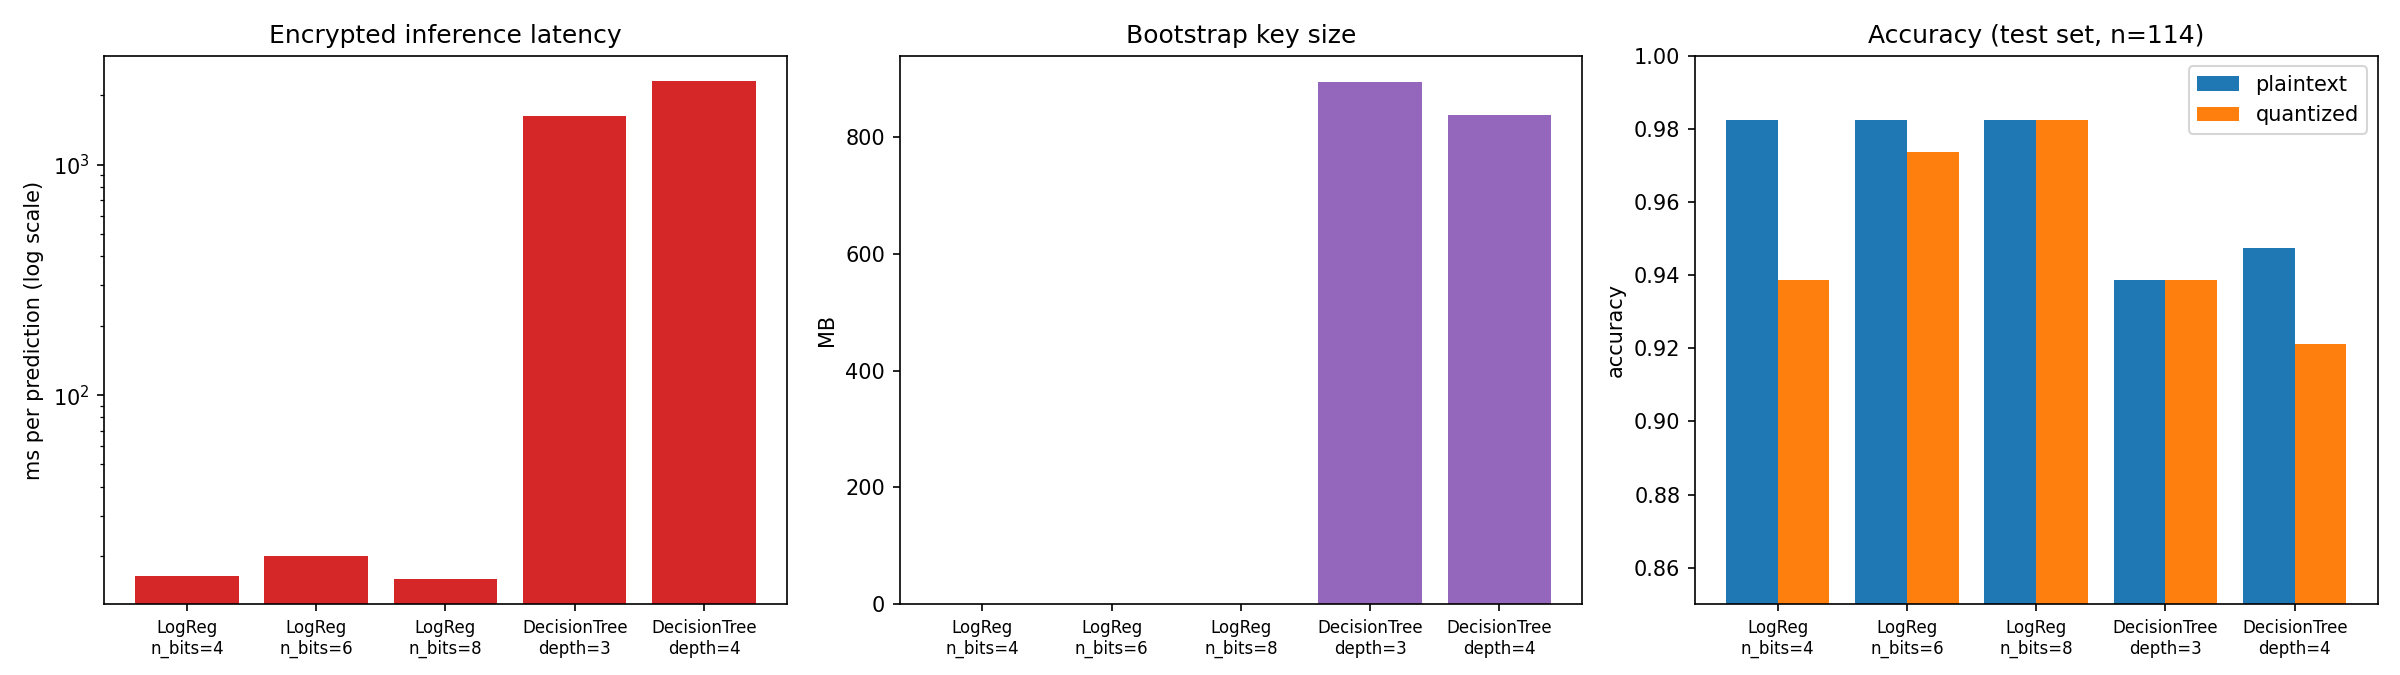

,model,config,plain_acc,quantized_clear_acc,fhe_eval_samples,fhe_acc_on_subset,agreement_with_clear,plain_ms_per_sample,fhe_ms_per_sample,compile_s,keygen_s,bootstraps,bootstrap_key_mb,keyswitch_key_mb
0,LogReg,n_bits=4,0.9825,0.9386,114,0.9386,1.0,0.02010,16.42,0.42,0.00,0,0.0,0.0
1,LogReg,n_bits=6,0.9825,0.9737,114,0.9737,1.0,0.01145,20.05,0.52,0.00,0,0.0,0.0
2,LogReg,n_bits=8,0.9825,0.9825,114,0.9825,1.0,0.00186,15.87,0.36,0.00,0,0.0,0.0
3,DecisionTree,depth=3,0.9386,0.9386,20,0.9500,1.0,0.00189,1634.17,2.33,9.60,55,894.3,89.2
4,DecisionTree,depth=4,0.9474,0.9211,20,0.9000,1.0,0.00234,2312.46,2.23,10.82,82,838.7,115.5


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from IPython.display import Image, display
import pandas as pd
display(Image("results.png"))
display(pd.read_csv("results.csv"))

from google.colab import files
files.download("results.csv")
files.download("results.png")